# Modelo comportamental

**Objetivo**

Este notebook treina o **modelo comportamental**, que estima o risco dos clientes recorrentes usando, além do cadastro, o histórico de pedidos.

Ele responde a três perguntas:
- qual algoritmo usar (regressão logística, Random Forest, XGBoost e LightGBM, com busca de parâmetros);
- quanto o histórico acrescenta ao modelo de aplicação, nos mesmos clientes;
- qual o score de cada cliente recorrente.

**Quem são os clientes recorrentes**

O enunciado define cliente ativo como quem comprou nos últimos 30 dias. A base não tem data de referência, então esse corte não pode ser aplicado.

Aqui, recorrente é quem tem histórico de pedidos liberado: 664 clientes, 531 no treino e 133 no teste. A seção 1.1 mostra por que o corte de 30 dias não pode ser aplicado e por que "quantos pedidos ele já fez" não entra.

**Regras**
- Features: as 10 do modelo de aplicação (`fa.FEATURES_FINAIS`) e as agregações dos pedidos (`src/features_comportamentais.py`), na versão com todos os pedidos, escolhida no notebook 04.
- Split e folds compartilhados (`src/split.py`): os mesmos do modelo de aplicação, para a comparação ser pareada.
- O modelo é treinado e avaliado **só nos clientes recorrentes**: é para eles que ele existe. Os clientes sem histórico de pedidos continuam com o modelo de aplicação.
- **Toda escolha usa só o treino.** O teste é usado **uma vez só**, na seção 9.
- Um modelo mais complexo só substitui um mais simples se ganhar mais de 1 erro padrão corrigido (`av.comparar`).
- Saídas só com agregados, nunca linhas de clientes (o repositório é público).

**Treino, validação e teste**

O enunciado pede split treino/validação/teste. Aqui a validação é a validação cruzada 5 folds × 5 repetições dentro do treino, e não um terceiro pedaço fixo.

Com 531 clientes recorrentes no treino, uma validação fixa de 20% teria uns 22 inadimplentes, e o AUC dela variaria muito de um sorteio para outro. Os 25 folds usam todos os clientes do treino na validação e dão um erro padrão para cada comparação.

## 1. Configuração e dados

Os resultados de `mc.validacao_cruzada` ficam guardados em `data/processed/cache_kan8/` (fora do git), com `joblib.Memory`. Se outra parte do `src/` mudar (features ou pré-processador), apague a pasta à mão.

In [1]:
# Standard
import sys
import warnings
from pathlib import Path

# Manipulação de dados
import numpy as np
import pandas as pd

# Visualização
import matplotlib.pyplot as plt

# Modelagem e métricas
from sklearn.base import clone
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve

# Cache das validações cruzadas
from joblib import Memory

# Módulos do projeto (src/)
sys.path.insert(0, str(Path.cwd().parent))
from src import avaliacao as av
from src import dados
from src import features_aplicacao as fa
from src import modelo_aplicacao as ma
from src import modelo_comportamental as mc
from src import split as sp

# Exibição das tabelas e avisos
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", message="X does not have valid feature names")

# Gráficos: pasta das figuras e paleta da EDA
FIG = Path("../reports/figures")
AZUL, LARANJA, VERDE, CINZA, TEXTO = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA, "axes.labelcolor": TEXTO,
    "xtick.color": TEXTO, "ytick.color": TEXTO, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "figure.dpi": 110,
})

# Cache das validações cruzadas
memoria = Memory(dados.DIR_PROCESSED / "cache_kan8", verbose=0)
vc = memoria.cache(mc.validacao_cruzada)

In [2]:
clientes, pedidos = dados.carregar_dados_limpos()
split = sp.carregar_split()
assert split.equals(sp.criar_split(clientes, pedidos))  # o mesmo split do modelo de aplicação
conjunto = clientes["id_cliente"].map(split)
com_pedidos = clientes["id_cliente"].isin(pedidos["id_cliente"])

X = mc.montar_X(clientes, pedidos)
treino = clientes[conjunto == "treino"].reset_index(drop=True)
cv = sp.folds(treino, pedidos)
X_treino = X[conjunto == "treino"].reset_index(drop=True)
y_treino = treino["inadimplente"]
tem_treino = com_pedidos[conjunto == "treino"].reset_index(drop=True)

print(f"treino: {len(X_treino)} clientes, {tem_treino.sum()} com pedidos "
      f"({y_treino[tem_treino].mean():.1%} inadimplentes entre eles) | {len(cv)} folds")
print(f"validação por fold: ~{np.mean([tem_treino.iloc[va].sum() for _, va in cv]):.0f} clientes com pedidos, "
      f"~{np.mean([y_treino[tem_treino].reindex(va).sum() for _, va in cv]):.0f} inadimplentes")

treino: 2400 clientes, 531 com pedidos (20.7% inadimplentes entre eles) | 25 folds
validação por fold: ~106 clientes com pedidos, ~22 inadimplentes


### 1.1 Quem é "cliente ativo" nesta base

O guia do desafio define o modelo comportamental para o **cliente ativo**, o que fez compra nos últimos 30 dias, e sugere variáveis como "quantos pedidos ele já fez", "em quantos atrasou" e "qual foi o atraso médio".

Duas características da base impedem seguir essa definição ao pé da letra. As células abaixo mostram as duas.

In [3]:
n_pedidos = pedidos.groupby("id_cliente").size()
print("Pedidos por cliente (clientes com histórico):")
display(n_pedidos.value_counts().sort_index().rename_axis("pedidos na base").rename("clientes").to_frame())

ultimo = pedidos.groupby("id_cliente")["data_entrega"].max()
fim = pedidos["data_entrega"].max()
print(f"Datas de entrega: de {pedidos['data_entrega'].min():%d/%m/%Y} a {fim:%d/%m/%Y}")
print("Ano do último pedido de cada cliente:")
display(ultimo.dt.year.value_counts().sort_index().rename_axis("ano").rename("clientes").to_frame())

dias = (fim - ultimo).dt.days
pd.Series({f"últimos {d} dias": int((dias <= d).sum()) for d in [30, 90, 180, 365]},
          name=f"clientes ativos contando a partir de {fim:%d/%m/%Y}").to_frame()

Pedidos por cliente (clientes com histórico):


,clientes
pedidos na base,
1,2
2,11
3,651


Datas de entrega: de 25/04/2022 a 01/04/2026
Ano do último pedido de cada cliente:


,clientes
ano,
2022,19
2023,449
2024,175
2025,18
2026,3


,clientes ativos contando a partir de 01/04/2026
últimos 30 dias,1
últimos 90 dias,3
últimos 180 dias,6
últimos 365 dias,14


**Leitura**

**1. A base traz no máximo os últimos 3 pedidos de cada cliente.**
- 651 dos 664 clientes com histórico têm exatamente 3 pedidos, 11 têm 2 e 2 têm 1. Ninguém tem mais de 3.
- Um teto exato indica que a Praso mandou só os 3 pedidos mais recentes, e não o histórico inteiro.
- Por isso **"quantos pedidos ele já fez" não pode ser calculado**: a contagem mediria o corte da extração, não o cliente. As variáveis de atraso sugeridas pelo guia ("em quantos atrasou", "atraso médio") são calculadas, mas sobre esses 3 pedidos: descrevem o comportamento **recente**, não o histórico inteiro.

**2. A base não é uma foto de um único dia.**
- Os últimos pedidos dos clientes vão de 2022 a 2026, e a maioria é de 2023.
- Aplicando o corte do guia a partir da data mais recente da base, sobraria **1 cliente** ativo nos últimos 30 dias. Mesmo com um ano de janela, sobrariam 14.
- Cada cliente parece ter sido registrado num momento diferente: os pedidos dele e, provavelmente, a inadimplência observada logo depois. A base não informa essa data de referência.

**Como o notebook trata isso**

Recorrente é **quem tem histórico de pedidos liberado** (664 clientes). A interpretação é que cada cliente era ativo no momento dele: tinha pedidos recentes quando a inadimplência foi observada.

É a aproximação possível com estes dados, e fica como limitação no relatório. Com a data de referência de cada cliente e o histórico completo, daria para aplicar o corte de 30 dias e contar os pedidos de verdade. É uma pergunta para levar à Praso.

A tabela de resultados de cada seção usa as mesmas colunas, sempre calculadas **só nos clientes com pedidos**:

| Coluna | O que é |
|---|---|
| AUC validação | média do ROC-AUC nos 25 folds de validação: a medida de desempenho |
| erro padrão | erro padrão corrigido da média (Nadeau e Bengio), porque os folds reaproveitam clientes |
| AUC treino | média do ROC-AUC nos clientes com pedidos usados para ajustar o modelo |
| treino − validação | quanto o modelo vai melhor nos clientes que viu: a medida de overfitting |

In [4]:
fator = np.sqrt(1 / len(cv) + len(cv[0][1]) / len(cv[0][0]))  # erro padrão corrigido = fator × desvio


def resumo(resultados: dict) -> pd.DataFrame:
    """AUC de validação (média e erro padrão corrigido), AUC de treino e a diferença entre os dois."""
    return pd.DataFrame({
        nome: {
            "AUC validação": r["auc_validacao"].mean(),
            "erro padrão": fator * r["auc_validacao"].std(ddof=1),
            "AUC treino": r["auc_treino"].mean(),
            "treino − validação": r["auc_treino"].mean() - r["auc_validacao"].mean(),
        }
        for nome, r in resultados.items()
    }).T


def comparacoes(pares: list[tuple]) -> pd.DataFrame:
    """Ganho pareado de AUC (com − sem) com a regra de 1 erro padrão corrigido."""
    return pd.DataFrame([
        {"item": item, **av.comparar(com["auc_validacao"], sem["auc_validacao"], cv)} for item, com, sem in pares
    ]).set_index("item")

## 2. Referência: o modelo de aplicação nos clientes recorrentes

É o XGBoost final do modelo de aplicação (`ma.PARAMS_FINAIS`), só com as 10 features de cadastro, treinado em todo o treino e avaliado nos clientes com pedidos.

Ele entra aqui sem a calibração, que não muda a ordem dos clientes (e portanto não muda o AUC). É o número que o modelo comportamental precisa superar.

In [5]:
APLICACAO = vc(mc.aplicacao_referencia(), X_treino, y_treino, cv, tem_treino, "todos")
resumo({"modelo de aplicação": APLICACAO})

,AUC validação,erro padrão,AUC treino,treino − validação
modelo de aplicação,0.691,0.031,0.774,0.083


## 3. Quais features de pedidos entram

O notebook 04 mostrou que o sinal está no **atraso** e que valor e ritmo não acrescentam com o atraso presente (seção 7). Aqui isso é conferido com os blocos já sem os pares redundantes (`mc.BLOCOS`):

In [6]:
pd.Series({nome: ", ".join(cols) for nome, cols in mc.BLOCOS.items()}, name="features").to_frame()

,features
atraso,"atraso_media, atraso_mediana, atraso_max, pct_..."
valor,"valor_media, valor_mediana, valor_min"
ritmo,"n_dias_com_pedido, intervalo_medio_dias"


Os blocos entram um de cada vez, na Random Forest com os parâmetros-base, treinada só nos clientes recorrentes do treino. Um bloco só fica se acrescentar mais de 1 erro padrão.

O ritmo é testado em dois passos, porque as duas features dele medem coisas diferentes:
- `intervalo_medio_dias` usa as datas: é a frequência recente de compra (dias entre um pedido e o seguinte);
- `n_dias_com_pedido` só conta em quantos dias diferentes os pedidos aconteceram. Como a base traz no máximo os últimos 3 pedidos de cada cliente, ela vale 1, 2 ou 3 e quase só diz se houve 2 pedidos no mesmo dia.

A ordem é da versão mais simples para a mais completa: só atraso → + intervalo → + ritmo completo. Cada passo só é dado se acrescentar mais de 1 erro padrão sobre o anterior.

A mesma comparação é mostrada também na regressão logística (C = 0,1), só como conferência: a decisão é tomada na Random Forest, antes da escolha do algoritmo.

In [7]:
ATRASO, VALOR, RITMO = mc.BLOCOS["atraso"], mc.BLOCOS["valor"], mc.BLOCOS["ritmo"]
INTERVALO = ["intervalo_medio_dias"]
blocos = {
    "aplicação + atraso": ATRASO,
    "+ valor": ATRASO + VALOR,
    "+ intervalo": ATRASO + INTERVALO,
    "+ ritmo": ATRASO + RITMO,
}
rf_blocos = {nome: vc(mc.random_forest(cols), X_treino, y_treino, cv, tem_treino, "com pedidos") for nome, cols in blocos.items()}
log_blocos = {nome: vc(mc.logistica(cols, C=0.1), X_treino, y_treino, cv, tem_treino, "com pedidos") for nome, cols in blocos.items()}

passos = [
    ("atraso, sobre o modelo de aplicação", "aplicação + atraso", None),
    ("valor, com o atraso", "+ valor", "aplicação + atraso"),
    ("intervalo, com o atraso", "+ intervalo", "aplicação + atraso"),
    ("n_dias_com_pedido, com atraso e intervalo", "+ ritmo", "+ intervalo"),
]
for titulo, res in [("Random Forest (decide)", rf_blocos), ("Regressão logística (conferência)", log_blocos)]:
    print(titulo)
    display(resumo({"modelo de aplicação": APLICACAO, **res}))
    display(comparacoes([(item, res[com], APLICACAO if sem is None else res[sem]) for item, com, sem in passos]))

Random Forest (decide)


,AUC validação,erro padrão,AUC treino,treino − validação
modelo de aplicação,0.691,0.031,0.774,0.083
aplicação + atraso,0.754,0.027,0.830,0.076
+ valor,0.756,0.028,0.832,0.076
+ intervalo,0.766,0.025,0.848,0.083
+ ritmo,0.766,0.025,0.849,0.083


,ganho,erro padrão,ganho / erro padrão,veredito
item,,,,
"atraso, sobre o modelo de aplicação",0.063,0.037,1.708,acrescenta
"valor, com o atraso",0.002,0.005,0.411,neutro
"intervalo, com o atraso",0.012,0.011,1.106,acrescenta
"n_dias_com_pedido, com atraso e intervalo",0.000,0.004,0.117,neutro


Regressão logística (conferência)


,AUC validação,erro padrão,AUC treino,treino − validação
modelo de aplicação,0.691,0.031,0.774,0.083
aplicação + atraso,0.732,0.031,0.793,0.061
+ valor,0.730,0.032,0.796,0.066
+ intervalo,0.733,0.031,0.797,0.064
+ ritmo,0.738,0.033,0.804,0.065


,ganho,erro padrão,ganho / erro padrão,veredito
item,,,,
"atraso, sobre o modelo de aplicação",0.041,0.030,1.349,acrescenta
"valor, com o atraso",-0.002,0.008,-0.198,neutro
"intervalo, com o atraso",0.001,0.006,0.147,neutro
"n_dias_com_pedido, com atraso e intervalo",0.006,0.006,0.889,neutro


In [8]:
# Regra: o atraso sempre entra. O valor entra se acrescentar sobre o atraso. O intervalo entra se acrescentar
# sobre o atraso, e n_dias_com_pedido só se acrescentar sobre atraso + intervalo.
def acrescenta(com, sem):
    return av.comparar(rf_blocos[com]["auc_validacao"], rf_blocos[sem]["auc_validacao"], cv)["veredito"] == "acrescenta"


PEDIDOS = list(ATRASO)
if acrescenta("+ valor", "aplicação + atraso"):
    PEDIDOS += VALOR
if acrescenta("+ intervalo", "aplicação + atraso"):
    PEDIDOS += INTERVALO
    if acrescenta("+ ritmo", "+ intervalo"):
        PEDIDOS += ["n_dias_com_pedido"]
print("features de pedidos:", ", ".join(PEDIDOS))

features de pedidos: atraso_media, atraso_mediana, atraso_max, pct_atraso, pct_atraso_2d, atraso_tendencia, intervalo_medio_dias


**Leitura**

- **O atraso é o que mais acrescenta.** Com ele, o AUC nos recorrentes sobe de 0,691 (modelo de aplicação) para 0,754 (+0,063, 1,7 erro padrão).
- **O valor não acrescenta** com o atraso no modelo (+0,002, neutro).
- **O intervalo entre pedidos acrescenta pouco e passa a regra por pouco:** +0,012, 1,1 erro padrão. Ele entra.
- **`n_dias_com_pedido` não acrescenta nada** com atraso e intervalo no modelo (0,000) e sai. Com a base limitada aos últimos 3 pedidos, ela quase só indicava pedidos no mesmo dia.
- Na logística, que aqui serve só de conferência, o atraso também acrescenta (+0,041), mas o intervalo não (+0,001).

**Features de pedidos:** as 6 de atraso e `intervalo_medio_dias`.

**Cuidado com o intervalo.** O ganho está no limite da regra e aparece só na Random Forest. Além disso, o notebook 04 avisou que o intervalo pode carregar parte do efeito de época (notebook 04, seção 4.2): sem data de referência, não se sabe quando os 3 pedidos aconteceram. Tirá-lo custa cerca de 0,012 de AUC.

## 4. Por que treinar só nos recorrentes

O modelo comportamental julga clientes que já fazem parte da recorrência. Por isso ele é treinado só com os 531 recorrentes do treino (110 inadimplentes), e não com os 2.400.

Seria possível treinar com todos, deixando as features de pedidos nulas para quem não tem histórico. Isso foi descartado por três motivos:
- **são populações diferentes:** os clientes sem histórico liberado são, em grande parte, clientes novos, com 34% de inadimplência contra 21% dos recorrentes;
- **o modelo gastaria divisões separando "tem pedidos" de "não tem"**, uma distinção que não existe entre os clientes que ele vai pontuar;
- **a calibração ficaria enviesada:** ajustada com todos, ela subestimava o risco dos recorrentes (17% previsto contra 21% observado).

A tabela abaixo mostra quanto essa escolha custa em AUC, com os parâmetros-base. É só para registro: a escolha é de escopo e não depende do resultado.

In [9]:
fabricas_base = {
    "logística (C = 0,1)": lambda: mc.logistica(PEDIDOS, C=0.1),
    "random forest": lambda: mc.random_forest(PEDIDOS),
    "xgboost": lambda: mc.xgboost(PEDIDOS),
    "lightgbm": lambda: mc.lightgbm(PEDIDOS),
}
populacao = {
    (nome, onde): vc(f(), X_treino, y_treino, cv, tem_treino, onde)
    for nome, f in fabricas_base.items() for onde in ("todos", "com pedidos")
}
display(resumo({f"{nome} | treino: {onde}": r for (nome, onde), r in populacao.items()}))
comparacoes([(f"{nome}: só com pedidos no lugar de todos", populacao[(nome, "com pedidos")], populacao[(nome, "todos")])
             for nome in fabricas_base])

,AUC validação,erro padrão,AUC treino,treino − validação
"logística (C = 0,1) | treino: todos",0.725,0.027,0.752,0.027
"logística (C = 0,1) | treino: com pedidos",0.733,0.031,0.797,0.064
random forest | treino: todos,0.785,0.025,0.873,0.087
random forest | treino: com pedidos,0.766,0.025,0.848,0.083
xgboost | treino: todos,0.763,0.026,0.953,0.190
xgboost | treino: com pedidos,0.728,0.030,0.986,0.258
lightgbm | treino: todos,0.759,0.028,0.965,0.206
lightgbm | treino: com pedidos,0.713,0.027,0.999,0.286


,ganho,erro padrão,ganho / erro padrão,veredito
item,,,,
"logística (C = 0,1): só com pedidos no lugar de todos",0.008,0.017,0.459,neutro
random forest: só com pedidos no lugar de todos,-0.020,0.017,-1.122,atrapalha
xgboost: só com pedidos no lugar de todos,-0.034,0.019,-1.828,atrapalha
lightgbm: só com pedidos no lugar de todos,-0.046,0.019,-2.438,atrapalha


In [10]:
# Decisão de escopo: todos os modelos são treinados só nos recorrentes.
POP = {nome.split(" (")[0]: "com pedidos" for nome in fabricas_base}
pd.Series(POP, name="treinar em").to_frame()

,treinar em
logística,com pedidos
random forest,com pedidos
xgboost,com pedidos
lightgbm,com pedidos


**Leitura**

- **Treinar só nos recorrentes custa AUC nas árvores:** −0,020 na Random Forest, −0,034 no XGBoost e −0,046 no LightGBM, com os parâmetros-base.
- O custo vem de os *boostings* decorarem o treino com 531 clientes: a distância entre treino e validação vai a 0,26 e 0,29. A busca da seção 6 procura configurações mais regularizadas para reduzir isso.
- **Na logística, não há custo** (+0,008, neutro).

A escolha fica mantida: o modelo é para os recorrentes, e o custo é o preço de não misturar populações diferentes.

## 5. Regressão logística

Mesma grade de `C` do modelo de aplicação (quanto menor, mais regularização). As features de pedidos são padronizadas. Entre os recorrentes, só há nulo em `atraso_tendencia` e `intervalo_medio_dias` de quem tem 1 pedido: ele é imputado pela mediana do treino, com uma coluna 0/1 marcando o nulo.

In [11]:
C_GRADE = [0.01, 0.03, 0.1, 0.3, 1, 3]
logisticas = {c: vc(mc.logistica(PEDIDOS, C=c), X_treino, y_treino, cv, tem_treino, POP["logística"]) for c in C_GRADE}
melhor_C = max(C_GRADE, key=lambda c: logisticas[c]["auc_validacao"].mean())
LOG = logisticas[melhor_C]
print("melhor C:", melhor_C, "| treino em:", POP["logística"])
resumo({f"C = {c}": r for c, r in logisticas.items()})

melhor C: 0.01 | treino em: com pedidos


,AUC validação,erro padrão,AUC treino,treino − validação
C = 0.01,0.748,0.029,0.785,0.037
C = 0.03,0.741,0.030,0.790,0.049
C = 0.1,0.733,0.031,0.797,0.064
C = 0.3,0.723,0.031,0.801,0.078
C = 1,0.712,0.032,0.803,0.091
C = 3,0.705,0.033,0.803,0.098


## 6. Busca de parâmetros

Busca aleatória com os mesmos espaços do modelo de aplicação (`ma.ESPACOS`), que já favorecem modelos regularizados: 20 configurações por algoritmo, sorteadas com a seed 42, avaliadas nos 25 folds.

Com tão poucos inadimplentes por fold, a melhor configuração de uma busca tende a ser otimista (ela foi escolhida justamente por ter ido bem nesses folds). Por isso a escolha final, na seção 7, exige ganho acima de 1 erro padrão.

Com 531 clientes, a busca importa mais que no modelo de aplicação: com os parâmetros-base, os *boostings* decoram o treino (seção 4), e os espaços incluem configurações mais regularizadas (árvores rasas, folhas maiores, mais penalização).

In [12]:
N_BUSCA = 20
busca = {}
for nome in mc.FABRICAS:
    configs = list(ParameterSampler(mc.ESPACOS[nome], n_iter=N_BUSCA, random_state=sp.SEED))
    busca[nome] = [(p, vc(mc.FABRICAS[nome](PEDIDOS, **p), X_treino, y_treino, cv, tem_treino, POP[nome])) for p in configs]
    print(f"{nome}: {len(configs)} configurações | treino em: {POP[nome]}")

melhores = {nome: max(res, key=lambda pr: pr[1]["auc_validacao"].mean()) for nome, res in busca.items()}
tab = resumo({nome: r for nome, (_, r) in melhores.items()})
tab["parâmetros"] = [str(p) for p, _ in melhores.values()]
tab

random forest: 20 configurações | treino em: com pedidos


xgboost: 20 configurações | treino em: com pedidos


lightgbm: 20 configurações | treino em: com pedidos


,AUC validação,erro padrão,AUC treino,treino − validação,parâmetros
random forest,0.766,0.025,0.841,0.075,"{'min_samples_leaf': 20, 'max_features': 'sqrt..."
xgboost,0.768,0.026,0.848,0.080,"{'subsample': 0.6, 'reg_lambda': 5, 'n_estimat..."
lightgbm,0.772,0.027,0.883,0.110,"{'subsample_freq': 1, 'subsample': 1.0, 'reg_l..."


## 7. Comparação e escolha do modelo

Candidatos, do mais simples para o mais complexo:
1. regressão logística (melhor C);
2. Random Forest com os parâmetros-base;
3. Random Forest, LightGBM e XGBoost da busca.

**Regra de escolha:** acha o candidato de maior AUC e fica com o **mais simples** que ele não supera por mais de 1 erro padrão corrigido.

In [13]:
candidatos = {
    "regressão logística": (lambda: mc.logistica(PEDIDOS, C=melhor_C), POP["logística"], LOG),
    "random forest (base)": (lambda: mc.random_forest(PEDIDOS), POP["random forest"], populacao[("random forest", POP["random forest"])]),
    "random forest (busca)": (lambda: mc.random_forest(PEDIDOS, **melhores["random forest"][0]), POP["random forest"], melhores["random forest"][1]),
    "lightgbm (busca)": (lambda: mc.lightgbm(PEDIDOS, **melhores["lightgbm"][0]), POP["lightgbm"], melhores["lightgbm"][1]),
    "xgboost (busca)": (lambda: mc.xgboost(PEDIDOS, **melhores["xgboost"][0]), POP["xgboost"], melhores["xgboost"][1]),
}
res_cand = {nome: r for nome, (_, _, r) in candidatos.items()}
melhor = max(res_cand, key=lambda n: res_cand[n]["auc_validacao"].mean())
FINAL = next(n for n in res_cand
             if av.comparar(res_cand[melhor]["auc_validacao"], res_cand[n]["auc_validacao"], cv)["veredito"] != "acrescenta")

tabela = resumo({"modelo de aplicação": APLICACAO, **res_cand})
tabela["vs. aplicação"] = [np.nan] + [res_cand[n]["auc_validacao"].mean() - APLICACAO["auc_validacao"].mean() for n in res_cand]
print("maior AUC:", melhor, "| escolhido:", FINAL)
display(tabela)
comparacoes([(f"{melhor} vs. {n}", res_cand[melhor], res_cand[n]) for n in res_cand if n != melhor]
            + [(f"{FINAL} vs. modelo de aplicação", res_cand[FINAL], APLICACAO)])

maior AUC: lightgbm (busca) | escolhido: random forest (base)


,AUC validação,erro padrão,AUC treino,treino − validação,vs. aplicação
modelo de aplicação,0.691,0.031,0.774,0.083,NaN
regressão logística,0.748,0.029,0.785,0.037,0.057
random forest (base),0.766,0.025,0.848,0.083,0.075
random forest (busca),0.766,0.025,0.841,0.075,0.075
lightgbm (busca),0.772,0.027,0.883,0.110,0.081
xgboost (busca),0.768,0.026,0.848,0.080,0.077


,ganho,erro padrão,ganho / erro padrão,veredito
item,,,,
lightgbm (busca) vs. regressão logística,0.025,0.020,1.253,acrescenta
lightgbm (busca) vs. random forest (base),0.007,0.014,0.468,neutro
lightgbm (busca) vs. random forest (busca),0.006,0.015,0.423,neutro
lightgbm (busca) vs. xgboost (busca),0.005,0.012,0.382,neutro
random forest (base) vs. modelo de aplicação,0.075,0.038,1.982,acrescenta


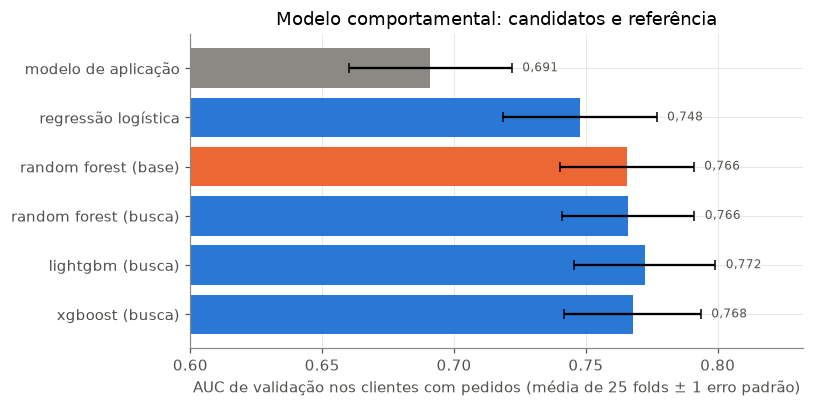

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
nomes = ["modelo de aplicação", *res_cand]
medias = [tabela.loc[n, "AUC validação"] for n in nomes]
erros = [tabela.loc[n, "erro padrão"] for n in nomes]
cores = [CINZA] + [LARANJA if n == FINAL else AZUL for n in res_cand]
ax.barh(nomes[::-1], medias[::-1], xerr=erros[::-1], color=cores[::-1], capsize=3)
ax.set_xlim(0.6, max(medias) + 0.06)
ax.set_xlabel("AUC de validação nos clientes com pedidos (média de 25 folds ± 1 erro padrão)")
ax.set_title("Modelo comportamental: candidatos e referência")
for i, (m, e) in enumerate(zip(medias[::-1], erros[::-1])):
    ax.text(m + e + 0.004, i, f"{m:.3f}".replace(".", ","), va="center", fontsize=8, color=TEXTO)
plt.tight_layout(); plt.savefig(FIG / "kan8_comparacao.png", dpi=150); plt.show()

**Leitura**

- **As árvores empatam entre si.** LightGBM (0,772), XGBoost (0,768) e as duas Random Forests (0,766) ficam a até 0,007 de distância, menos de 1 erro padrão.
- **A logística (0,748) fica abaixo do LightGBM por pouco mais de 1 erro padrão** (+0,025, 1,25 erro padrão), e por isso sai.
- **Pela regra, o modelo escolhido é a Random Forest com os parâmetros-base**, o mais simples entre os que empatam com o melhor. A busca de parâmetros não acrescentou nada.
- **O histórico acrescenta ao modelo de aplicação:** de 0,691 para 0,766 nos mesmos clientes e nos mesmos folds (+0,075, 2,0 erros padrão).

**A escolha entre logística e árvores é frágil.** Com `n_dias_com_pedido` no modelo, a logística tinha 0,753 e empatava com o LightGBM pela regra. Tirar uma feature de efeito nulo bastou para mudar o modelo escolhido. Na prática, os candidatos estão muito próximos, e a regra decide por margens pequenas.

## 8. Calibração

**O que é**

O modelo dá a cada cliente um número entre 0 e 1: a chance de ele não pagar. Para esse número ser útil na política de crédito, ele precisa **bater com a realidade**: entre os clientes que receberam por volta de 20%, uns 20% devem de fato não pagar.

Um modelo pode acertar a **ordem** dos clientes (quem é mais arriscado que quem) e mesmo assim errar a **escala** (dizer 40% para um grupo em que só 25% não pagam). É como uma balança que sempre marca 2 kg a mais: ela diz certo quem é mais pesado, mas o número está errado.

**Calibrar** é um passo extra, depois do modelo, que corrige a escala. Aqui é a calibração sigmoide (`mc.calibrado`): ela aprende, com clientes que o modelo não viu, uma curva que transforma o número do modelo na chance real. A ordem dos clientes não muda, então o AUC também não.

**Como conferir se o número bate com a realidade**

Não dá para conferir olhando um cliente só: se o modelo disse 40% para alguém, essa pessoa só pode pagar ou não pagar. Por isso os clientes são agrupados:
1. os 531 recorrentes do treino são postos em fila, do menor score para o maior;
2. a fila é cortada em 5 grupos do mesmo tamanho (uns 106 clientes cada);
3. em cada grupo, compara-se a média do score (o previsto) com a fração que de fato não pagou (o real).

Se o modelo está calibrado, as duas colunas ficam próximas em todos os grupos. Os scores usados são os fora da amostra (seção 10): cada cliente é pontuado por modelos que não o viram.

**Regra**

A calibração só fica se reduzir o erro das probabilidades. A medida é o **Brier**: a média de (score − resultado)², em que o resultado é 1 se o cliente não pagou e 0 se pagou. Quanto menor, melhor. A calibração fica se reduzir o Brier em pelo menos 1%; senão, sai, porque é uma etapa a mais sem ganho.

In [15]:
def fora_da_amostra(r):
    """Score fora da amostra dos clientes com pedidos do treino (média das 5 repetições)."""
    return mc.score_fora_da_amostra({"pred": r["pred"][:, tem_treino.to_numpy()]})


def por_grupo(score, n=5):
    """Clientes em fila pelo score, cortados em n grupos iguais: previsto (score médio) contra real."""
    d = pd.DataFrame({"score": score, "inadimplente": y_rec})
    d["grupo"] = pd.qcut(d["score"], n, labels=range(1, n + 1))
    return d.groupby("grupo", observed=True).agg(
        clientes=("score", "size"), score_de=("score", "min"), score_ate=("score", "max"),
        previsto=("score", "mean"), nao_pagaram=("inadimplente", "sum"), real=("inadimplente", "mean"),
    )


y_rec = y_treino[tem_treino].to_numpy()
fabrica_final, POP_FINAL, RES_FINAL = candidatos[FINAL]
CAL = vc(mc.calibrado(fabrica_final()), X_treino, y_treino, cv, tem_treino, POP_FINAL)
score_sem, score_cal = fora_da_amostra(RES_FINAL), fora_da_amostra(CAL)

brier = {"sem calibrar": brier_score_loss(y_rec, score_sem), "calibrado": brier_score_loss(y_rec, score_cal)}
display(pd.DataFrame({
    "score médio": [score_sem.mean(), score_cal.mean(), y_rec.mean()],
    "AUC": [roc_auc_score(y_rec, score_sem), roc_auc_score(y_rec, score_cal), np.nan],
    "Brier": [brier["sem calibrar"], brier["calibrado"], np.nan],
}, index=[f"{FINAL}, sem calibrar", f"{FINAL}, calibrado", "real (taxa de inadimplência)"]))

print("Grupos pelo score sem calibrar")
display(por_grupo(score_sem))
print("Grupos pelo score calibrado")
display(por_grupo(score_cal))

# Regra: a calibração só fica se reduzir o Brier em pelo menos 1%.
CALIBRAR = brier["calibrado"] < 0.99 * brier["sem calibrar"]
MODELO_FINAL = CAL if CALIBRAR else RES_FINAL
score_oof = score_cal if CALIBRAR else score_sem
print(f"Brier: {brier['sem calibrar']:.4f} sem calibrar, {brier['calibrado']:.4f} calibrado "
      f"→ a calibração {'fica' if CALIBRAR else 'sai'}")

,score médio,AUC,Brier
"random forest (base), sem calibrar",0.207,0.763,0.141
"random forest (base), calibrado",0.211,0.761,0.141
real (taxa de inadimplência),0.207,NaN,NaN


Grupos pelo score sem calibrar


,clientes,score_de,score_ate,previsto,nao_pagaram,real
grupo,,,,,,
1,107,0.020,0.098,0.064,3,0.028
2,106,0.098,0.142,0.120,10,0.094
3,106,0.142,0.216,0.175,24,0.226
4,106,0.216,0.327,0.265,27,0.255
5,106,0.328,0.534,0.416,46,0.434


Grupos pelo score calibrado


,clientes,score_de,score_ate,previsto,nao_pagaram,real
grupo,,,,,,
1,107,0.055,0.089,0.073,2,0.019
2,106,0.090,0.119,0.104,12,0.113
3,106,0.119,0.188,0.147,23,0.217
4,106,0.188,0.335,0.247,26,0.245
5,106,0.336,0.688,0.487,47,0.443


Brier: 0.1407 sem calibrar, 0.1405 calibrado → a calibração sai


**Leitura**

**A Random Forest treinada só nos recorrentes já sai calibrada.**
- O score médio sem calibrar é **20,7%**, igual à taxa real de inadimplência dos recorrentes (110 de 531, 20,7%).
- Nos 5 grupos, o previsto fica perto do real. Por exemplo, no grupo de maior risco o modelo previu 41,6% e 43,4% não pagaram; no de menor risco, previu 6,4% e 2,8% não pagaram.
- A ordem funciona: do grupo 1 ao 5, a inadimplência real sobe de 2,8% para 43,4%.

**A calibração não melhora nada.**
- O Brier quase não muda (0,1407 sem calibrar, 0,1405 calibrado): menos de 1%.
- Ela só troca erros de lugar: aproxima o grupo 4, mas afasta o 3 (previsto 14,7% para 21,7% reais) e o 5 (48,7% para 44,3%).

**A calibração sai.** O modelo final é a Random Forest sem calibração.

Por que aqui ela não faz falta, e no modelo de aplicação fazia? Quando o modelo era treinado com todos os clientes, ele aprendia o risco de uma população misturada (34% de inadimplência sem histórico, 21% com histórico), e o score subestimava o risco dos recorrentes (17% para 21% reais). Treinado só nos recorrentes, ele aprende direto o risco deles.

### 8.1 Corte

**O que é**

O score é uma chance, mas precisão, recall e F1 pedem uma resposta de sim ou não. O **corte** é a linha que separa as duas:
- score **abaixo** do corte: o modelo diz "vai pagar";
- score **igual ou acima** do corte: o modelo diz "não vai pagar".

Com essa linha, dá para contar os acertos e os erros:
- **precisão:** dos clientes que o modelo marcou como "não vai pagar", quantos de fato não pagaram;
- **recall:** dos clientes que não pagaram, quantos o modelo marcou;
- **F1:** um equilíbrio entre as duas (a média harmônica);
- **% aprovados:** quantos clientes ficaram abaixo do corte.

**Qual corte**

O corte de 0,5 não faz sentido aqui: só 21% dos recorrentes não pagam, e quase ninguém passaria de 50%. O corte usado é o que dá o maior F1 nos scores fora da amostra do treino, calculado para cada modelo. Ele existe só para comparar os modelos nessas métricas.

O corte da política de crédito é outra decisão: depende de quanto a Praso perde com quem não paga e de quanto ganha com quem paga.

In [16]:
NOME_FINAL = "modelo comportamental (final)"
cortes = {n: mc.corte_f1(y_rec, fora_da_amostra(r)) for n, r in res_cand.items()}
cortes[NOME_FINAL] = CORTE = mc.corte_f1(y_rec, score_oof)
scores_apl = ma.carregar_scores().set_index("id_cliente")["score"]
score_apl_treino = scores_apl.reindex(treino.loc[tem_treino, "id_cliente"]).to_numpy()
cortes["modelo de aplicação"] = mc.corte_f1(y_rec, score_apl_treino)

pd.DataFrame({n: {"corte": cortes[n], **mc.metricas_no_corte(y_rec, s, cortes[n])} for n, s in [
    ("modelo de aplicação", score_apl_treino),
    (NOME_FINAL, score_oof),
]}).T

,corte,precisão,recall,F1,% aprovados
modelo de aplicação,0.252,0.326,0.682,0.441,0.567
modelo comportamental (final),0.284,0.442,0.555,0.492,0.740


**Leitura**

- **Corte do modelo comportamental:** 0,284. Quem tem score de 28,4% ou mais é tratado como "não vai pagar".
- Nesse corte, a **precisão** é de 0,442: de cada 100 clientes marcados, 44 de fato não pagaram. O **recall** é de 0,555: o modelo marcou 55% dos que não pagaram. F1 de 0,492, com 74% dos clientes aprovados.
- **Modelo de aplicação** no corte dele (0,252): precisão de 0,326, recall de 0,682, F1 de 0,441, 57% aprovados.
- O comportamental acerta mais quando marca alguém (44% contra 33%) e aprova mais clientes, mas deixa passar mais inadimplentes (recall de 0,555 contra 0,682). Mover o corte troca uma coisa pela outra; a escolha final é da política de crédito.

## 9. Avaliação final no teste

Com todas as escolhas feitas, cada candidato é ajustado no treino (só nos recorrentes) e avaliado **uma vez** nos 133 clientes recorrentes do teste.

- AUC com intervalo de 95% por bootstrap (2.000 reamostragens).
- Diferença para o modelo de aplicação nos mesmos clientes, com bootstrap pareado.
- Precisão, recall e F1 no corte de cada modelo, escolhido no treino (seção 8).
- Tempo de inferência: `predict_proba` nos 133 clientes de uma vez e em 1 cliente (mediana de 20 repetições), nesta máquina.

Com só 28 inadimplentes, o erro padrão do AUC fica perto de 0,05: o teste confirma a ordem de grandeza, mas não separa candidatos próximos.

In [17]:
teste_rec = (conjunto == "teste") & com_pedidos
X_teste, y_teste = X[teste_rec], clientes.loc[teste_rec, "inadimplente"].to_numpy()
ids_teste = clientes.loc[teste_rec, "id_cliente"]
mask_tr = (conjunto == "treino").to_numpy()


def ajustar(fabrica, onde):
    linhas_fit = mask_tr if onde == "todos" else mask_tr & com_pedidos.to_numpy()
    return fabrica().fit(X[linhas_fit], clientes.loc[linhas_fit, "inadimplente"])


modelos = {n: ajustar(f, onde) for n, (f, onde, _) in candidatos.items()}
modelos[NOME_FINAL] = FINAL_AJUSTADO = ajustar(lambda: mc.calibrado(fabrica_final()) if CALIBRAR else fabrica_final(), POP_FINAL)

score_teste = {"modelo de aplicação": scores_apl.reindex(ids_teste).to_numpy()}
score_teste |= {n: m.predict_proba(X_teste)[:, 1] for n, m in modelos.items()}

linhas = []
for n, s in score_teste.items():
    linha = {"modelo": n, **mc.auc_bootstrap(y_teste, s), **mc.metricas_no_corte(y_teste, s, cortes[n])}
    if n != "modelo de aplicação":
        dif = mc.diferenca_bootstrap(y_teste, s, score_teste["modelo de aplicação"])
        linha |= {"vs. aplicação": dif["diferença"], "IC dif inf": dif["IC inf"], "IC dif sup": dif["IC sup"]}
        t = mc.tempo_inferencia(modelos[n], X_teste)
        linha |= {"ms (133 clientes)": t["ms por lote"], "ms (1 cliente)": t["ms para 1 cliente"]}
    linhas.append(linha)
TESTE = pd.DataFrame(linhas).set_index("modelo")
TESTE

,AUC,IC inf,IC sup,precisão,recall,F1,% aprovados,vs. aplicação,IC dif inf,IC dif sup,ms (133 clientes),ms (1 cliente)
modelo,,,,,,,,,,,,
modelo de aplicação,0.670,0.552,0.775,0.315,0.607,0.415,0.594,NaN,NaN,NaN,NaN,NaN
regressão logística,0.789,0.690,0.878,0.415,0.786,0.543,0.602,0.119,0.017,0.228,10.642,10.467
random forest (base),0.740,0.638,0.835,0.381,0.571,0.457,0.684,0.070,-0.060,0.203,135.891,94.881
random forest (busca),0.740,0.640,0.833,0.381,0.571,0.457,0.684,0.070,-0.058,0.204,96.145,72.996
lightgbm (busca),0.735,0.638,0.823,0.345,0.679,0.458,0.586,0.065,-0.048,0.178,8.091,7.763
xgboost (busca),0.738,0.639,0.829,0.333,0.750,0.462,0.526,0.068,-0.052,0.193,32.322,23.254
modelo comportamental (final),0.740,0.638,0.835,0.381,0.571,0.457,0.684,0.070,-0.060,0.203,118.685,94.920


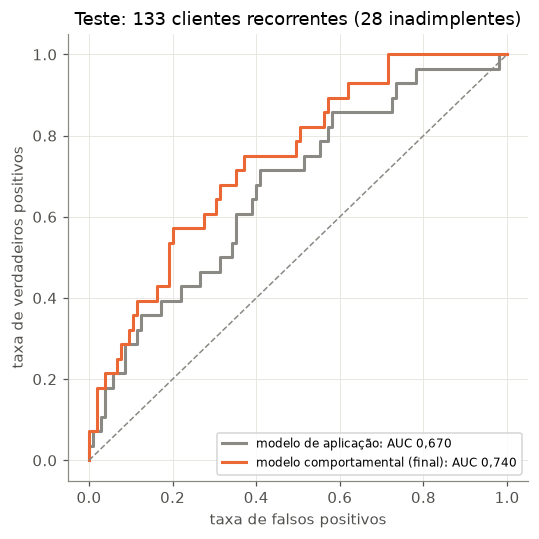

In [18]:
fig, ax = plt.subplots(figsize=(5, 5))
for n, cor in [("modelo de aplicação", CINZA), (NOME_FINAL, LARANJA)]:
    fpr, tpr, _ = roc_curve(y_teste, score_teste[n])
    ax.plot(fpr, tpr, color=cor, lw=2, label=f"{n}: AUC {TESTE.loc[n, 'AUC']:.3f}".replace(".", ","))
ax.plot([0, 1], [0, 1], color=CINZA, lw=1, ls="--")
ax.set_xlabel("taxa de falsos positivos"); ax.set_ylabel("taxa de verdadeiros positivos")
ax.set_title(f"Teste: {len(y_teste)} clientes recorrentes ({y_teste.sum()} inadimplentes)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "kan8_roc_teste.png", dpi=150); plt.show()

**Leitura**

- **O modelo comportamental (Random Forest) tem AUC de 0,740 no teste** (IC de 0,638 a 0,835), contra 0,670 do modelo de aplicação nos mesmos 133 clientes.
- **A diferença é de +0,070, mas o intervalo dela (−0,060 a +0,203) cruza o zero.** Com 28 inadimplentes, o teste sozinho não confirma o ganho. A evidência vem da validação cruzada (+0,075, 2,0 erros padrão); o teste vai na mesma direção.
- **A logística vai melhor no teste** (0,789, com diferença para o modelo de aplicação de +0,017 a +0,228). Os intervalos dela e da Random Forest se sobrepõem quase inteiros, então o teste não separa os dois. O modelo escolhido não muda: escolher pelo teste seria usá-lo duas vezes.
- **No corte escolhido no treino**, o comportamental tem precisão de 0,381 e recall de 0,571 (F1 de 0,457), contra 0,315 e 0,607 (F1 de 0,415) do modelo de aplicação. Ele acerta mais quando marca alguém e aprova mais clientes (68% contra 59%).
- **Tempo de inferência:** a Random Forest leva cerca de 0,1 s por chamada, para 1 cliente ou para os 133, quase tudo para abrir as 300 árvores em paralelo. LightGBM, XGBoost e logística ficam entre 10 e 30 ms. Os tempos variam com a carga da máquina; nesta escala, não são critério de escolha.

**Transparência sobre o teste.** Versões anteriores deste notebook (treino em todos os clientes; ritmo completo; calibração) chegaram a ser avaliadas no teste. As mudanças foram decididas pelo escopo do modelo (seção 4), pelo significado das features (seção 3) e pela regra da calibração (seção 8), e a escolha do algoritmo continua sendo feita só com a validação cruzada.

## 10. Score de cada cliente recorrente

Mesma regra do modelo de aplicação:
- **treino:** fora da amostra, a média das 5 predições de validação do modelo final (seção 8). Um cliente nunca recebe score de um modelo que o viu no ajuste;
- **teste:** do modelo final, ajustado no treino.

Só os clientes com pedidos recebem score. Ficam em `data/processed/scores_comportamental.csv` (fora do git).

In [19]:
ids_treino_rec = treino.loc[tem_treino, "id_cliente"]
scores = pd.concat([
    pd.DataFrame({"id_cliente": ids_treino_rec.to_numpy(), "conjunto": "treino", "score": score_oof}),
    pd.DataFrame({"id_cliente": ids_teste.to_numpy(), "conjunto": "teste", "score": score_teste[NOME_FINAL]}),
], ignore_index=True)
mc.salvar_scores(scores)

alvo = clientes.set_index("id_cliente")["inadimplente"]
scores["inadimplente"] = scores["id_cliente"].map(alvo)
scores["score aplicação"] = scores["id_cliente"].map(scores_apl)
display(scores.groupby("conjunto")[["score", "score aplicação", "inadimplente"]].mean()
        .rename(columns={"score": "score médio", "score aplicação": "score médio (aplicação)", "inadimplente": "taxa observada"}))

t = scores[scores["conjunto"] == "treino"].copy()
t["decil"] = pd.qcut(t["score"], 10, labels=range(1, 11))
t.groupby("decil", observed=True).agg(clientes=("score", "size"), score_medio=("score", "mean"), taxa=("inadimplente", "mean"))

,score médio,score médio (aplicação),taxa observada
conjunto,,,
teste,0.220,0.261,0.211
treino,0.207,0.284,0.207


,clientes,score_medio,taxa
decil,,,
1,54,0.047,0.000
2,53,0.080,0.057
3,53,0.109,0.094
4,53,0.131,0.094
5,53,0.155,0.151
6,53,0.194,0.302
7,53,0.238,0.208
8,53,0.292,0.302
9,53,0.369,0.264


## 11. Checagens

In [20]:
assert len(scores) == com_pedidos.sum() and scores["id_cliente"].is_unique
assert set(scores.loc[scores["conjunto"] == "teste", "id_cliente"]) == set(ids_teste)
assert scores["score"].between(0, 1).all()
assert not set(fa.FEATURES_FINAIS + PEDIDOS) & {"id_cliente", "inadimplente", "tem_pedidos"}
# score fora da amostra: cada cliente recorrente do treino foi previsto em exatamente 5 folds (1 por repetição)
assert (np.isfinite(MODELO_FINAL["pred"][:, tem_treino.to_numpy()]).sum(axis=0) == sp.N_REPETICOES).all()
print("ok")

ok


## 12. Resumo

**Escolhas** (todas no treino)
- **População:** treino e avaliação só nos clientes recorrentes (531 no treino, 110 inadimplentes). O modelo é para eles; quem não tem histórico de pedidos fica com o modelo de aplicação (seção 4).
- **Features:** as 10 do modelo de aplicação, as 6 de atraso (`atraso_media`, `atraso_mediana`, `atraso_max`, `pct_atraso`, `pct_atraso_2d`, `atraso_tendencia`) e `intervalo_medio_dias`. Valor e `n_dias_com_pedido` não acrescentam (seção 3).
- **Modelo final: Random Forest com os parâmetros-base, sem calibração.** As árvores empatam, e a regra fica com a mais simples (seção 7). Treinada só nos recorrentes, ela já sai calibrada, e a calibração não reduz o erro das probabilidades (seção 8).

**Validação cruzada** (531 clientes recorrentes do treino, 25 folds)

| Modelo | AUC validação | vs. modelo de aplicação |
|---|---|---|
| modelo de aplicação (referência) | 0,691 | — |
| regressão logística (C = 0,01) | 0,748 | +0,057 |
| **Random Forest (base): modelo final** | **0,766** | **+0,075 (2,0 erros padrão)** |
| Random Forest (busca) | 0,766 | +0,075 |
| XGBoost (busca) | 0,768 | +0,077 |
| LightGBM (busca) | 0,772 | +0,081 |

**Teste** (133 clientes recorrentes, 28 inadimplentes)
- AUC de 0,740 (IC de 0,638 a 0,835), contra 0,670 do modelo de aplicação. A diferença (+0,070) tem IC que cruza o zero: o teste é pequeno demais para confirmar o ganho sozinho.
- F1 de 0,457 contra 0,415, com precisão maior (0,381 contra 0,315) e recall parecido (0,571 contra 0,607).
- Inferência de cerca de 0,1 s por chamada.

**Score**

Fica em `data/processed/scores_comportamental.csv` (fora do git), só para os 664 clientes recorrentes. Para ler: `mc.carregar_scores()`.
- O score bate com a realidade: média de 20,7% (treino) e 22,0% (teste), para 20,7% e 21,1% observados.
- Por decil de score, a taxa de inadimplência vai de 0% a 60,4% no treino.

**Limitações e próximos passos**
- **Cliente ativo:** o corte de 30 dias do guia não pode ser aplicado. Os últimos pedidos vão de 2022 a 2026, e a partir da data mais recente da base sobraria 1 cliente ativo. "Recorrente" aqui é quem tem histórico de pedidos liberado, considerado ativo no momento dele (seção 1.1).
- **Histórico truncado:** a base traz no máximo os últimos 3 pedidos de cada cliente. "Quantos pedidos ele já fez", sugerido pelo guia, não pode ser calculado, e as features de atraso descrevem o comportamento recente (seção 1.1).
- Pergunta para a Praso: a data de referência de cada cliente e o histórico completo de pedidos permitiriam aplicar o corte de 30 dias e contar os pedidos.
- O intervalo entre pedidos entrou por pouco e pode carregar efeito de época (seção 3).
- A escolha entre logística e árvores é frágil (seção 7), e o teste não separa as duas (seção 9).
- Para a política de crédito: definir os cortes com os scores do treino (fora da amostra) e conferir no teste.